In [2]:

from google.colab import files

uploaded = files.upload()


Saving SMSSpamCollection to SMSSpamCollection


In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

file_path = Path("/content/SMSSpamCollection")

if not file_path.exists():
    raise FileNotFoundError(
        "SMSSpamCollection not found. Upload the dataset first."
    )

df = pd.read_csv(
    file_path,
    sep="\t",
    header=None,
    names=["label", "message"],
    encoding="utf-8"
)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
display(df.head())


Dataset loaded successfully!
Shape: (5572, 2)


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [4]:

print("Dataset shape:", df.shape)

print("\nColumn data types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isna().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nLabel distribution:")
print(df["label"].value_counts())

print("\nLabel percentages:")
print(
    (df["label"].value_counts(normalize=True) * 100)
    .round(2)
)


Dataset shape: (5572, 2)

Column data types:
label      object
message    object
dtype: object

Missing values:
label      0
message    0
dtype: int64

Duplicate rows: 403

Label distribution:
label
ham     4825
spam     747
Name: count, dtype: int64

Label percentages:
label
ham     86.59
spam    13.41
Name: proportion, dtype: float64


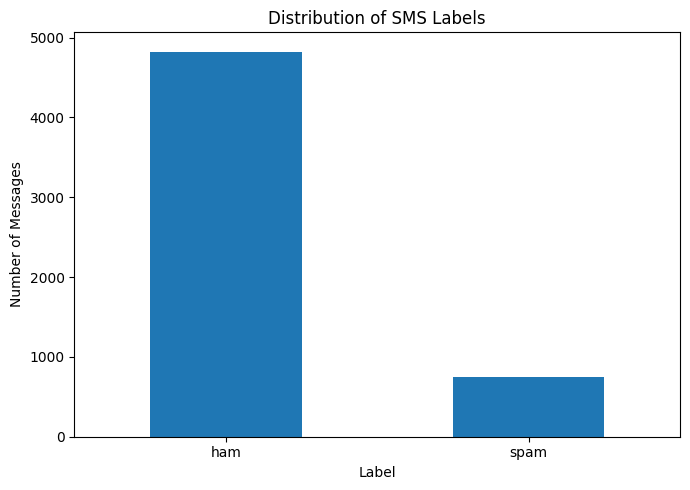

In [5]:

label_counts = df["label"].value_counts()

plt.figure(figsize=(7, 5))
label_counts.plot(kind="bar")
plt.title("Distribution of SMS Labels")
plt.xlabel("Label")
plt.ylabel("Number of Messages")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [6]:

# Inspect repeated message records
duplicate_mask = df.duplicated(keep=False)
duplicate_records = df[duplicate_mask].sort_values("message")

print("Rows belonging to duplicate groups:", duplicate_mask.sum())
print("Exact duplicate rows beyond first occurrences:", df.duplicated().sum())

# Check whether identical message text has conflicting labels
label_counts_per_message = df.groupby("message")["label"].nunique()

conflicting_messages = label_counts_per_message[
    label_counts_per_message > 1
]

print(
    "\nUnique message texts with conflicting labels:",
    len(conflicting_messages)
)

if len(conflicting_messages) > 0:
    display(
        df[df["message"].isin(conflicting_messages.index)]
        .sort_values("message")
        .head(20)
    )

# Preview repeated records
display(duplicate_records.head(10))


Rows belonging to duplicate groups: 684
Exact duplicate rows beyond first occurrences: 403

Unique message texts with conflicting labels: 0


,label,message
505,spam,+123 Congratulations - in this week's competit...
2124,spam,+123 Congratulations - in this week's competit...
2344,ham,1) Go to write msg 2) Put on Dictionary mode 3...
1373,ham,1) Go to write msg 2) Put on Dictionary mode 3...
2163,ham,1) Go to write msg 2) Put on Dictionary mode 3...
1050,spam,18 days to Euro2004 kickoff! U will be kept in...
2719,spam,18 days to Euro2004 kickoff! U will be kept in...
2044,spam,4mths half price Orange line rental & latest c...
389,spam,4mths half price Orange line rental & latest c...
1779,ham,7 wonders in My WORLD 7th You 6th Ur style 5th...


Message length statistics:


character_count                 word_count                
                 mean median min  max       mean median min  max
label                                                           
ham             71.48   52.0   2  910      14.31   11.0   1  171
spam           138.67  149.0  13  223      23.91   25.0   2   35

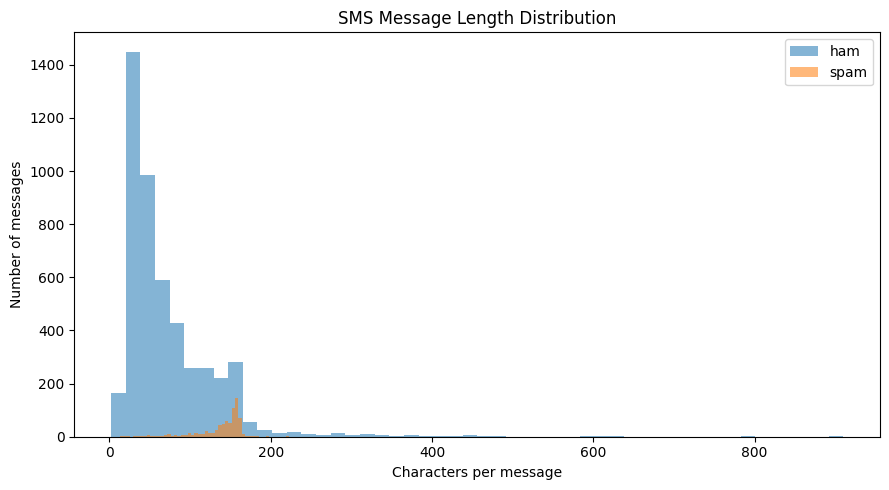

In [7]:

df["character_count"] = df["message"].str.len()
df["word_count"] = df["message"].str.split().str.len()

print("Message length statistics:")
display(
    df.groupby("label")[["character_count", "word_count"]]
    .agg(["mean", "median", "min", "max"])
    .round(2)
)

# Character count distribution
plt.figure(figsize=(9, 5))

for label in ["ham", "spam"]:
    subset = df.loc[df["label"] == label, "character_count"]
    plt.hist(subset, bins=50, alpha=0.55, label=label)

plt.title("SMS Message Length Distribution")
plt.xlabel("Characters per message")
plt.ylabel("Number of messages")
plt.legend()
plt.tight_layout()
plt.show()
